In [98]:
import numpy as np
import pandas as pd
import sklearn
import torchvision



In [99]:
df=pd.read_csv('Telco-Customer-Churn.csv')
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [100]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [101]:
df['Churn']

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: object

In [102]:
import matplotlib.pyplot as plt

departed=df[df['Churn']=='Yes']['MonthlyCharges']
remaining=df[df['Churn']=='No']['MonthlyCharges']

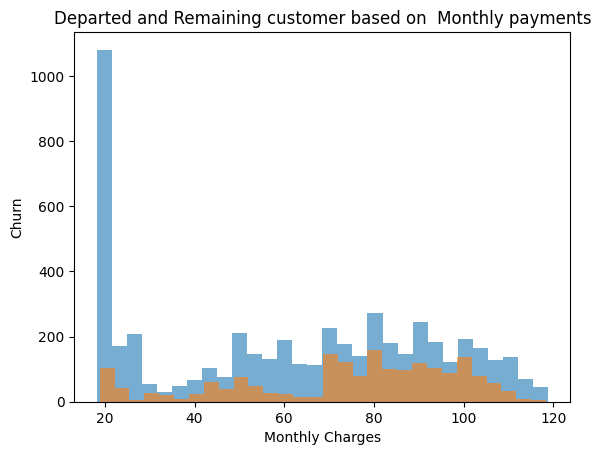

In [103]:
plt.hist(remaining, bins=30, alpha=0.6, label='Remaining Customer')
plt.hist(departed, bins=30, alpha=0.6, label='Departed Customer')
plt.xlabel("Monthly Charges")
plt.ylabel("Churn")
plt.title("Departed and Remaining customer based on  Monthly payments")
plt.show()

In [104]:
df_copy=df

In [105]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [106]:

df_copy['TotalCharges'] = pd.to_numeric(df_copy['TotalCharges'], errors='coerce')

print(df_copy['TotalCharges'].isna().sum())


df_copy['TotalCharges'] = df_copy['TotalCharges'].fillna(df_copy['TotalCharges'].median())

11


In [107]:
df_copy['Churn'] = df_copy['Churn'].map({'Yes': 1, 'No': 0})
x = df_copy.drop(columns=['Churn','customerID'])
y = df_copy['Churn']

In [108]:
x_encoder=pd.get_dummies(x)

In [109]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x_encoder, y, test_size=0.2, random_state=42
)

In [110]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [111]:
lr=LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)
lr_pred=lr.predict(X_test)

rf=RandomForestClassifier(n_estimators=100,random_state=42)
rf.fit(X_train,y_train)
rf_pred=rf.predict(X_test)

print("Logistic Regression")
print("  Accuracy :", accuracy_score(y_test, lr_pred))
print("  Precision:", precision_score(y_test, lr_pred))
print("  Recall   :", recall_score(y_test, lr_pred))

print("Random Forest")
print("  Accuracy :", accuracy_score(y_test, rf_pred))
print("  Precision:", precision_score(y_test, rf_pred))
print("  Recall   :", recall_score(y_test, rf_pred))

c:\Users\hp\anaconda3\envs\py3.10-pytorch\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression
  Accuracy : 0.8211497515968772
  Precision: 0.6850152905198776
  Recall   : 0.6005361930294906
Random Forest
  Accuracy : 0.7963094393186657
  Precision: 0.6604477611940298
  Recall   : 0.4745308310991957


In [112]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
X_train_s=scaler.fit_transform(X_train)
X_test_s=scaler.fit_transform(X_test)


In [113]:
lr2 = LogisticRegression(max_iter=1000)
lr2.fit(X_train_s, y_train)
lr2_pred = lr2.predict(X_test_s)

print("Logistic Regression (masshtablangan)")
print("  Accuracy :", accuracy_score(y_test, lr2_pred))
print("  Precision:", precision_score(y_test, lr2_pred))
print("  Recall   :", recall_score(y_test, lr2_pred))

Logistic Regression (masshtablangan)
  Accuracy : 0.8204400283889283
  Precision: 0.6840490797546013
  Recall   : 0.5978552278820375


In [114]:
print(X_train.shape)

(5634, 45)


In [115]:
# masshtablanmagan
lr = LogisticRegression(max_iter=5000).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

for nom, model, Xt in [("LR", lr, X_test), ("RF", rf, X_test)]:
    p = model.predict(Xt)
    print(nom, accuracy_score(y_test, p), precision_score(y_test, p), recall_score(y_test, p))

# masshtablangan LR
print("LR scaled", accuracy_score(y_test, lr2_pred), precision_score(y_test, lr2_pred), recall_score(y_test, lr2_pred))

LR 0.8211497515968772 0.6861538461538461 0.5978552278820375
RF 0.7963094393186657 0.6604477611940298 0.4745308310991957
LR scaled 0.8204400283889283 0.6840490797546013 0.5978552278820375


In [116]:
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

# Masshtablash (yangi 45 ustunli ma'lumot bilan qaytadan)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train.astype(float))
X_test_s = scaler.transform(X_test.astype(float))

# PyTorch tensorlariga aylantirish
X_tr = torch.tensor(X_train_s, dtype=torch.float32)
y_tr = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_te = torch.tensor(X_test_s, dtype=torch.float32)

print(X_tr.shape, y_tr.shape)

torch.Size([5634, 45]) torch.Size([5634, 1])


In [117]:
# Model: 45 -> 32 -> 16 -> 1
model = nn.Sequential(
    nn.Linear(45, 32),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# O'qitish
for epoch in range(100):
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(X_tr), y_tr)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}, loss: {loss.item():.4f}")

Epoch 10, loss: 0.6553
Epoch 20, loss: 0.6071
Epoch 30, loss: 0.5550
Epoch 40, loss: 0.5137
Epoch 50, loss: 0.4860
Epoch 60, loss: 0.4683
Epoch 70, loss: 0.4606
Epoch 80, loss: 0.4551
Epoch 90, loss: 0.4496
Epoch 100, loss: 0.4450


In [118]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

model.eval()
with torch.no_grad():
    prob = torch.sigmoid(model(X_te))
    nn_pred = (prob > 0.5).int().numpy()

print("Neyron tarmoq")
print("  Accuracy :", accuracy_score(y_test, nn_pred))
print("  Precision:", precision_score(y_test, nn_pred))
print("  Recall   :", recall_score(y_test, nn_pred))

Neyron tarmoq
  Accuracy : 0.8140525195173882
  Precision: 0.7063197026022305
  Recall   : 0.5093833780160858
